<a href="https://www.kaggle.com/code/fareedhassan/updated-tda-and-classical-ml-integration?scriptVersionId=367131191" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# TDA-Enhanced Breast Cancer Classification
**Pipeline:** PCA → kNN graph → Persistent Homology (Rips) → Persistence Images → Classifier

**Corrections applied:**
- k = 130 (was 15)
- MAX_EDGE recalibrated to 95th percentile of kNN distances **on PCA-reduced data**
- kNN graph fitted on training samples only inside each CV fold
- PCA fitted on training data only inside each fold (no test leakage)
- Persistence Images at 5×5 resolution (50 topological features per patient)

**Reference:** Adams et al. (2017). Persistence images: a stable vector representation of persistent homology. *JMLR*, 18(8).

In [1]:
# ── Install dependencies ───────────────────────────────────
# gudhi is not preinstalled on Kaggle. If this fails with a network/connection
# error rather than finishing cleanly, check the notebook's right-hand sidebar:
# Settings → Internet must be switched ON for pip to reach PyPI.
!pip install -q gudhi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 53.1 MB/s eta 0:00:0000:0100:01


In [2]:
# ── Imports ───────────────────────────────────────────────────
import numpy as np
import pandas as pd
import gudhi
import gudhi.representations
import warnings
warnings.filterwarnings('ignore')

from sklearn.decomposition        import PCA
from sklearn.neighbors            import NearestNeighbors
from sklearn.model_selection      import StratifiedKFold
from sklearn.pipeline             import Pipeline
from sklearn.preprocessing        import StandardScaler
from sklearn.linear_model         import LogisticRegression
from sklearn.svm                  import SVC
from sklearn.ensemble             import RandomForestClassifier
from sklearn.base                 import clone
from sklearn.metrics              import roc_auc_score, f1_score

In [3]:
# ── Load data ─────────────────────────────────────────────────
clean_df = pd.read_csv('/kaggle/input/notebooks/chibuikennadozie/cleaned-data/clean_data.csv')
X_orig   = clean_df.drop(columns=['diagnosis']).values
y        = clean_df['diagnosis'].values
print(f'Dataset shape: {X_orig.shape}')

Dataset shape: (569, 30)


In [4]:
# ── Global parameters ─────────────────────────────────────────
#
# K        : neighbourhood size for local Rips complex
# N_PCA    : PCA variance threshold (fitted per fold on training data only)
# PI_RES   : persistence image grid resolution (PI_RES × PI_RES per homology dim)
#
# MAX_EDGE is NOT set here.  It is calibrated below on one representative
# PCA projection of the full data, then used as a fixed global constant.
# Because PCA compresses pairwise distances relative to the raw 30-D space,
# the raw-data value of 8.7 would be too large and admit no finite bars.

K      = 130
N_PCA  = 0.95     # retain components explaining 95% of variance
PI_RES = 5        # yields 2 × 5 × 5 = 50 topological features per patient

In [5]:
# ── MAX_EDGE calibration on PCA-reduced data ──────────────────
#
# We run PCA once on the full dataset to get a representative reduced
# dimension, then compute 95th-percentile of K-NN distances in that space.
# This is not used for any model fitting — purely to set the filtration bound.

pca_ref        = PCA(n_components=N_PCA, random_state=42).fit(X_orig)
X_pca_ref      = pca_ref.transform(X_orig)
d_pca          = X_pca_ref.shape[1]

nbrs_ref       = NearestNeighbors(n_neighbors=K + 1).fit(X_pca_ref)
dists_ref, _   = nbrs_ref.kneighbors(X_pca_ref)
MAX_EDGE       = float(np.percentile(dists_ref[:, 1:], 95))

print(f'PCA retains {d_pca} components ({N_PCA*100:.0f}% variance)')
print(f'Recalibrated MAX_EDGE: {MAX_EDGE:.4f}')

PCA retains 10 components (95% variance)
Recalibrated MAX_EDGE: 1.0403


In [6]:
# ── PH pipeline helpers ───────────────────────────────────────

def compute_diagrams(X_train_pca, X_query_pca):
    """
    Build kNN graph on X_train_pca only, then compute persistence diagrams
    for each patient in X_query_pca using their local K-neighbourhood.

    Parameters
    ----------
    X_train_pca : ndarray of shape (n_train, d_pca)
        PCA-reduced training points used to fit the kNN index.
    X_query_pca : ndarray of shape (n_query, d_pca)
        PCA-reduced points whose diagrams are to be computed.
        Pass X_train_pca again to get training diagrams.

    Returns
    -------
    h0_diags, h1_diags : lists of length n_query
        Each element is a float array of shape (n_bars, 2) with columns
        [birth, death].  Empty complexes return shape (0, 2).
    """
    nbrs     = NearestNeighbors(n_neighbors=K + 1).fit(X_train_pca)
    _, idx   = nbrs.kneighbors(X_query_pca)

    h0_diags, h1_diags = [], []

    for i in range(len(X_query_pca)):
        local_pts = X_train_pca[idx[i, :K]]
        rips      = gudhi.RipsComplex(points=local_pts, max_edge_length=MAX_EDGE)
        st        = rips.create_simplex_tree(max_dimension=2)
        st.compute_persistence()
        diag      = st.persistence()

        def finite_bars(dim):
            bars = np.array([[b, d] for (d_i, (b, d)) in diag
                             if d_i == dim and d != float('inf')])
            return bars if len(bars) > 0 else np.empty((0, 2))

        h0_diags.append(finite_bars(0))
        h1_diags.append(finite_bars(1))

    return h0_diags, h1_diags


def fit_pi_transformers(h0_diags, h1_diags):
    """
    Fit one PersistenceImage transformer per homology dimension
    on the training diagrams.

    Weight function: w(x) = x[1]^2  (persistence squared).
    This down-weights short-lived noise and amplifies robust features.
    """
    pi_h0 = gudhi.representations.PersistenceImage(
        bandwidth=0.5,
        weight=lambda x: x[1] ** 2,
        resolution=[PI_RES, PI_RES]
    ).fit(h0_diags)

    pi_h1 = gudhi.representations.PersistenceImage(
        bandwidth=0.5,
        weight=lambda x: x[1] ** 2,
        resolution=[PI_RES, PI_RES]
    ).fit(h1_diags)

    return pi_h0, pi_h1


def transform_to_pi(pi_h0, pi_h1, h0_diags, h1_diags):
    """
    Apply fitted PI transformers and concatenate H0 and H1 feature vectors.

    Returns array of shape (n, 2 * PI_RES * PI_RES).
    """
    feat_h0 = pi_h0.transform(h0_diags)   # (n, PI_RES^2)
    feat_h1 = pi_h1.transform(h1_diags)   # (n, PI_RES^2)
    return np.hstack([feat_h0, feat_h1])   # (n, 2*PI_RES^2)

## Visual diagnostics: persistence structures for individual patients

Before running the full cross-validated comparison, it helps to see what the local topological
neighbourhood of a single patient actually looks like. The cell below picks **2 malignant and
2 benign patients at random** (fixed seed for reproducibility) and, for each one, plots:

- the **persistence barcode** of their local Vietoris–Rips neighbourhood (H0 in red, H1 in blue),
- the corresponding **persistence diagram**,
- the **persistence image** actually used as the 50-D feature vector (left half = H0, right half = H1).

These four patients' diagrams are computed once on the **full, PCA-reduced point cloud**, purely for
illustration. They are **not** part of the leakage-controlled cross-validation loop below, which refits
PCA, the k-NN graph, and the persistence-image transformer inside each fold separately.

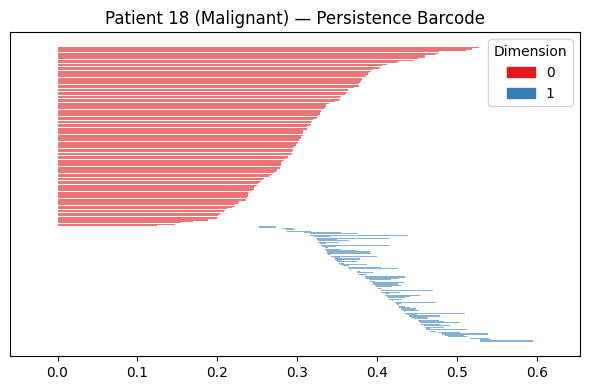

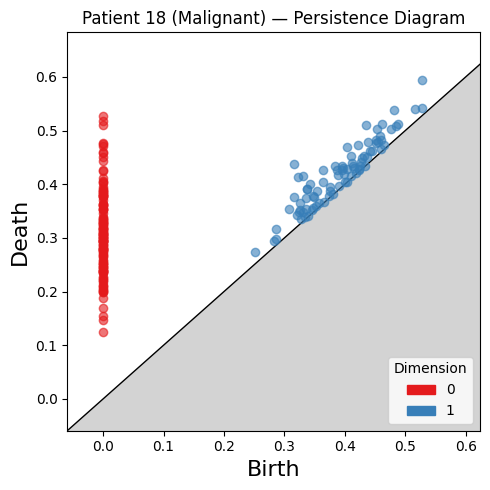

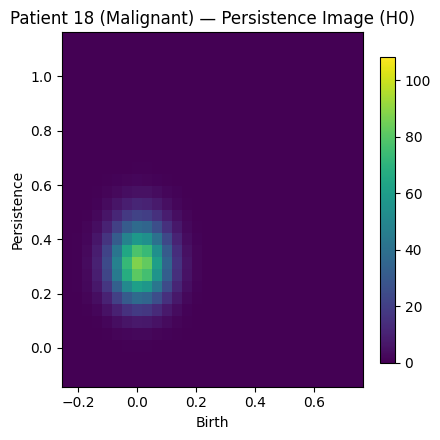

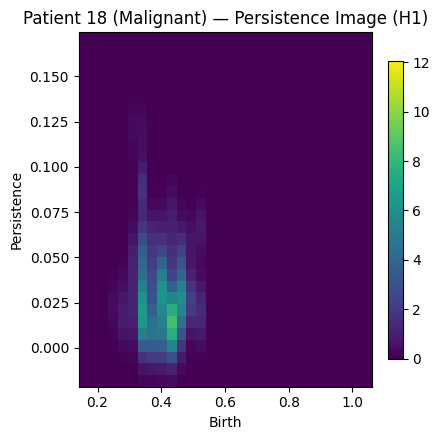

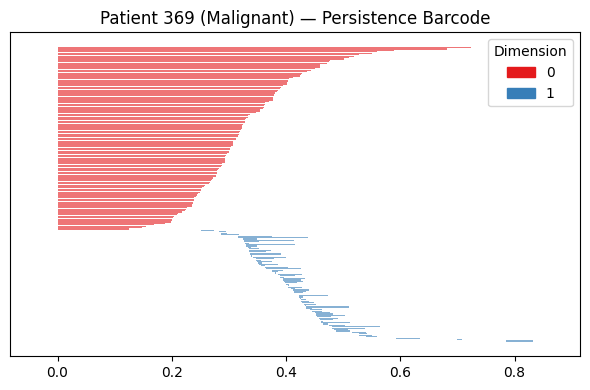

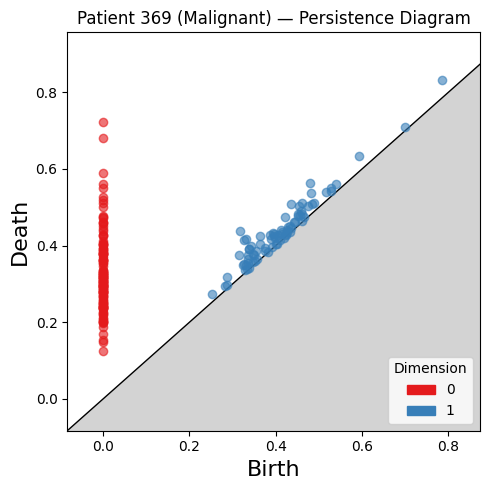

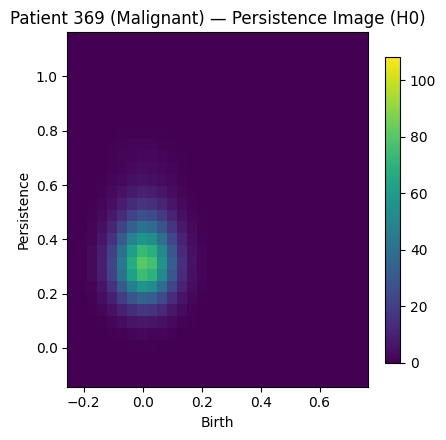

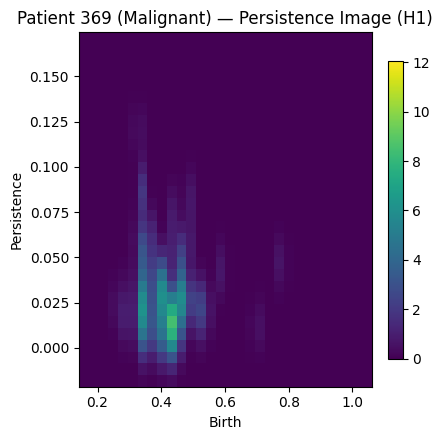

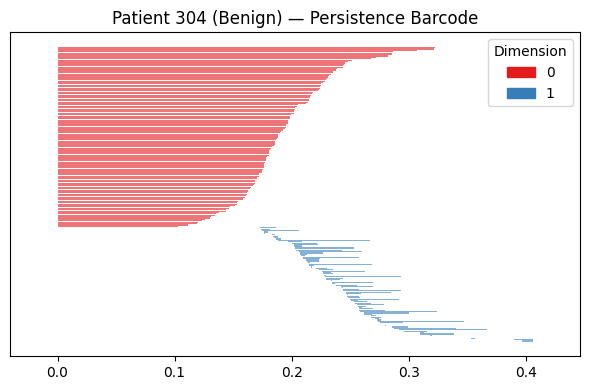

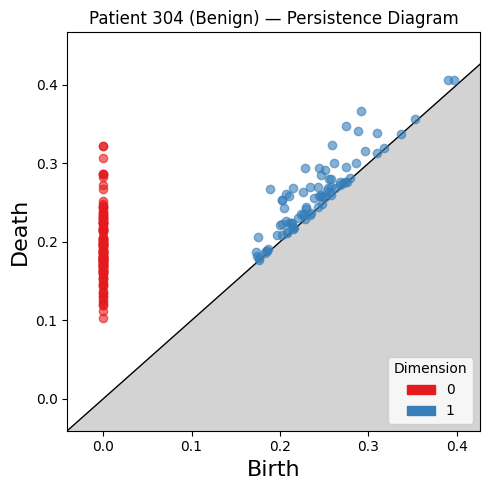

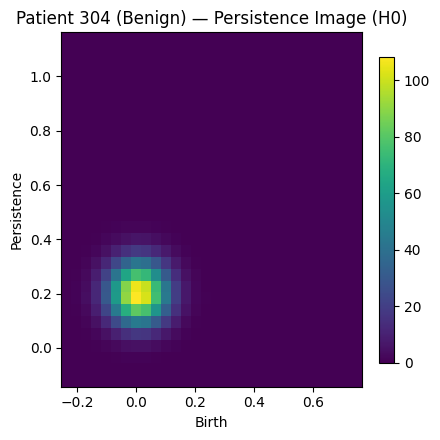

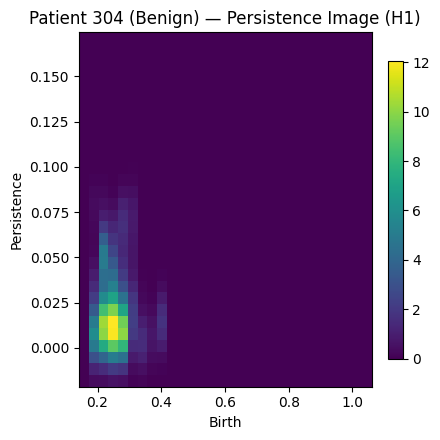

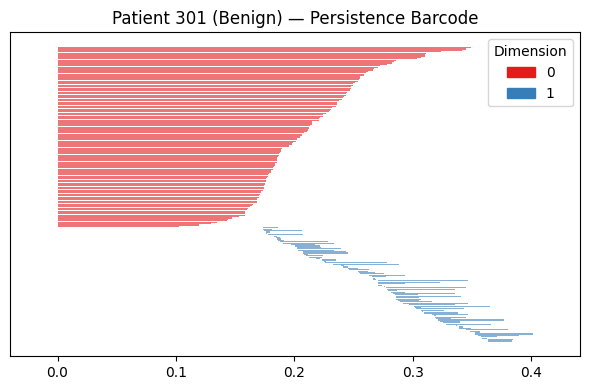

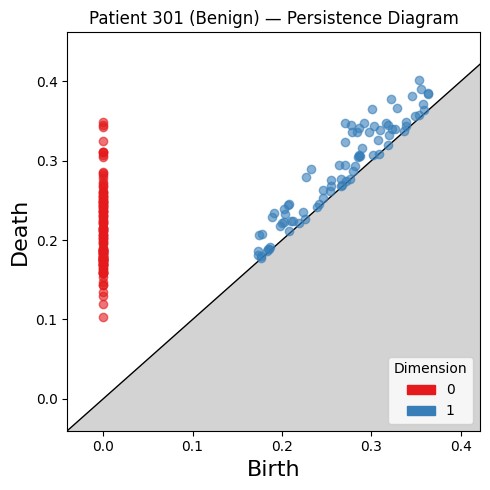

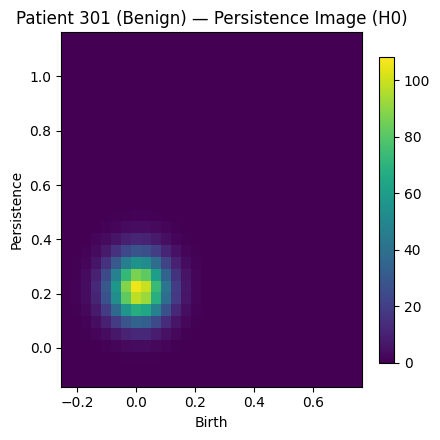

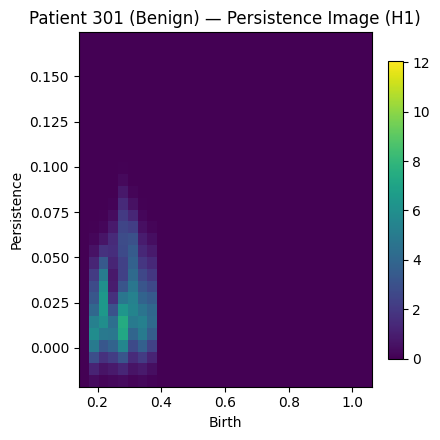

In [7]:
# ── Sample-level visualisation: one figure per plot, per patient ─────
# 2 malignant + 2 benign patients, chosen at random (seed=42) purely for illustration.
# Uses the full-data PCA cloud (X_pca_ref) computed in the MAX_EDGE calibration cell above,
# NOT the per-fold train/test split used in the CV loop below.
# Each patient produces 4 separate figures: barcode, diagram, PI(H0), PI(H1).

import numpy as np
import matplotlib.pyplot as plt
import gudhi

VIZ_RES = 30   # coarse grid gives the pixelated look of your reference

# ── 1. Same patients as before ──
rng              = np.random.default_rng(42)
benign_idx       = np.where(y == 0)[0]
malignant_idx    = np.where(y == 1)[0]
sample_malignant = rng.choice(malignant_idx, size=2, replace=False)
sample_benign    = rng.choice(benign_idx,    size=2, replace=False)
sample_idx       = np.concatenate([sample_malignant, sample_benign])
sample_labels    = ['Malignant', 'Malignant', 'Benign', 'Benign']

# ── 2. Diagrams (single source for ALL four plot types) ──
h0_all, h1_all = compute_diagrams(X_pca_ref, X_pca_ref)

def finite(d):
    d = np.asarray(d, dtype=float).reshape(-1, 2)
    return d[np.isfinite(d).all(axis=1)]

h0_all = [finite(d) for d in h0_all]
h1_all = [finite(d) for d in h1_all]

# ── 3. Persistence image computed directly (birth on x, persistence on y) ──
def pi_range(diagrams, is_h0, sigma_frac=0.07):
    pts = np.vstack([d for d in diagrams if len(d)] or [np.zeros((1, 2))])
    b, p = pts[:, 0], pts[:, 1] - pts[:, 0]
    pmax  = max(p.max(), 1e-8)
    sigma = sigma_frac * pmax
    if is_h0:                                   # all births are 0 -> give the blob room
        b_lo, b_hi = -0.25 * pmax, 0.75 * pmax
    else:
        pad = 3 * sigma
        b_lo, b_hi = b.min() - pad, b.max() + pad
        if b_hi - b_lo < 1e-8:
            b_lo, b_hi = b_lo - 0.25 * pmax, b_hi + 0.75 * pmax
    return (b_lo, b_hi, -2 * sigma, pmax + 2 * sigma), sigma

def persistence_image(dgm, rng_, sigma, res):
    b_lo, b_hi, p_lo, p_hi = rng_
    xs = np.linspace(b_lo, b_hi, res)
    ys = np.linspace(p_lo, p_hi, res)
    img = np.zeros((res, res))
    if len(dgm) == 0:
        return img
    b, p = dgm[:, 0], dgm[:, 1] - dgm[:, 0]
    Gx = np.exp(-(xs[None, :] - b[:, None])**2 / (2 * sigma**2))   # (n, res)
    Gy = np.exp(-(ys[None, :] - p[:, None])**2 / (2 * sigma**2))   # (n, res)
    return Gy.T @ Gx            # rows = persistence, cols = birth (constant weight)

rng0, s0 = pi_range(h0_all, True)
rng1, s1 = pi_range(h1_all, False)

imgs0 = {i: persistence_image(h0_all[i], rng0, s0, VIZ_RES) for i in sample_idx}
imgs1 = {i: persistence_image(h1_all[i], rng1, s1, VIZ_RES) for i in sample_idx}
vmax0 = max(a.max() for a in imgs0.values())
vmax1 = max(a.max() for a in imgs1.values())

# ── 4. Plots ──
for i, label in zip(sample_idx, sample_labels):
    diag_i = [(0, tuple(bar)) for bar in h0_all[i]] + [(1, tuple(bar)) for bar in h1_all[i]]

    # Barcode
    plt.figure(figsize=(6, 4))
    gudhi.plot_persistence_barcode(diag_i, axes=plt.gca(), legend=True)
    plt.title(f'Patient {i} ({label}) — Persistence Barcode')
    plt.tight_layout()
    plt.savefig(f'barcode_patient_{i}_{label.lower()}.png', dpi=150, bbox_inches='tight')
    plt.show()

    # Diagram
    plt.figure(figsize=(5, 5))
    gudhi.plot_persistence_diagram(diag_i, axes=plt.gca(), legend=True)
    plt.title(f'Patient {i} ({label}) — Persistence Diagram')
    plt.tight_layout()
    plt.savefig(f'diagram_patient_{i}_{label.lower()}.png', dpi=150, bbox_inches='tight')
    plt.show()

    # Persistence images (H0, H1)
    for name, img, vmax, r in [('H0', imgs0[i], vmax0, rng0),
                               ('H1', imgs1[i], vmax1, rng1)]:
        plt.figure(figsize=(4.5, 4.5))
        plt.imshow(img, cmap='viridis', origin='lower', vmin=0, vmax=vmax,
                   extent=[r[0], r[1], r[2], r[3]], aspect='auto',
                   interpolation='nearest')
        plt.title(f'Patient {i} ({label}) — Persistence Image ({name})')
        plt.xlabel('Birth'); plt.ylabel('Persistence')
        plt.colorbar(fraction=0.046)
        plt.tight_layout()
        plt.savefig(f'pi_{name.lower()}_patient_{i}_{label.lower()}.png',
                    dpi=150, bbox_inches='tight')
        plt.show()

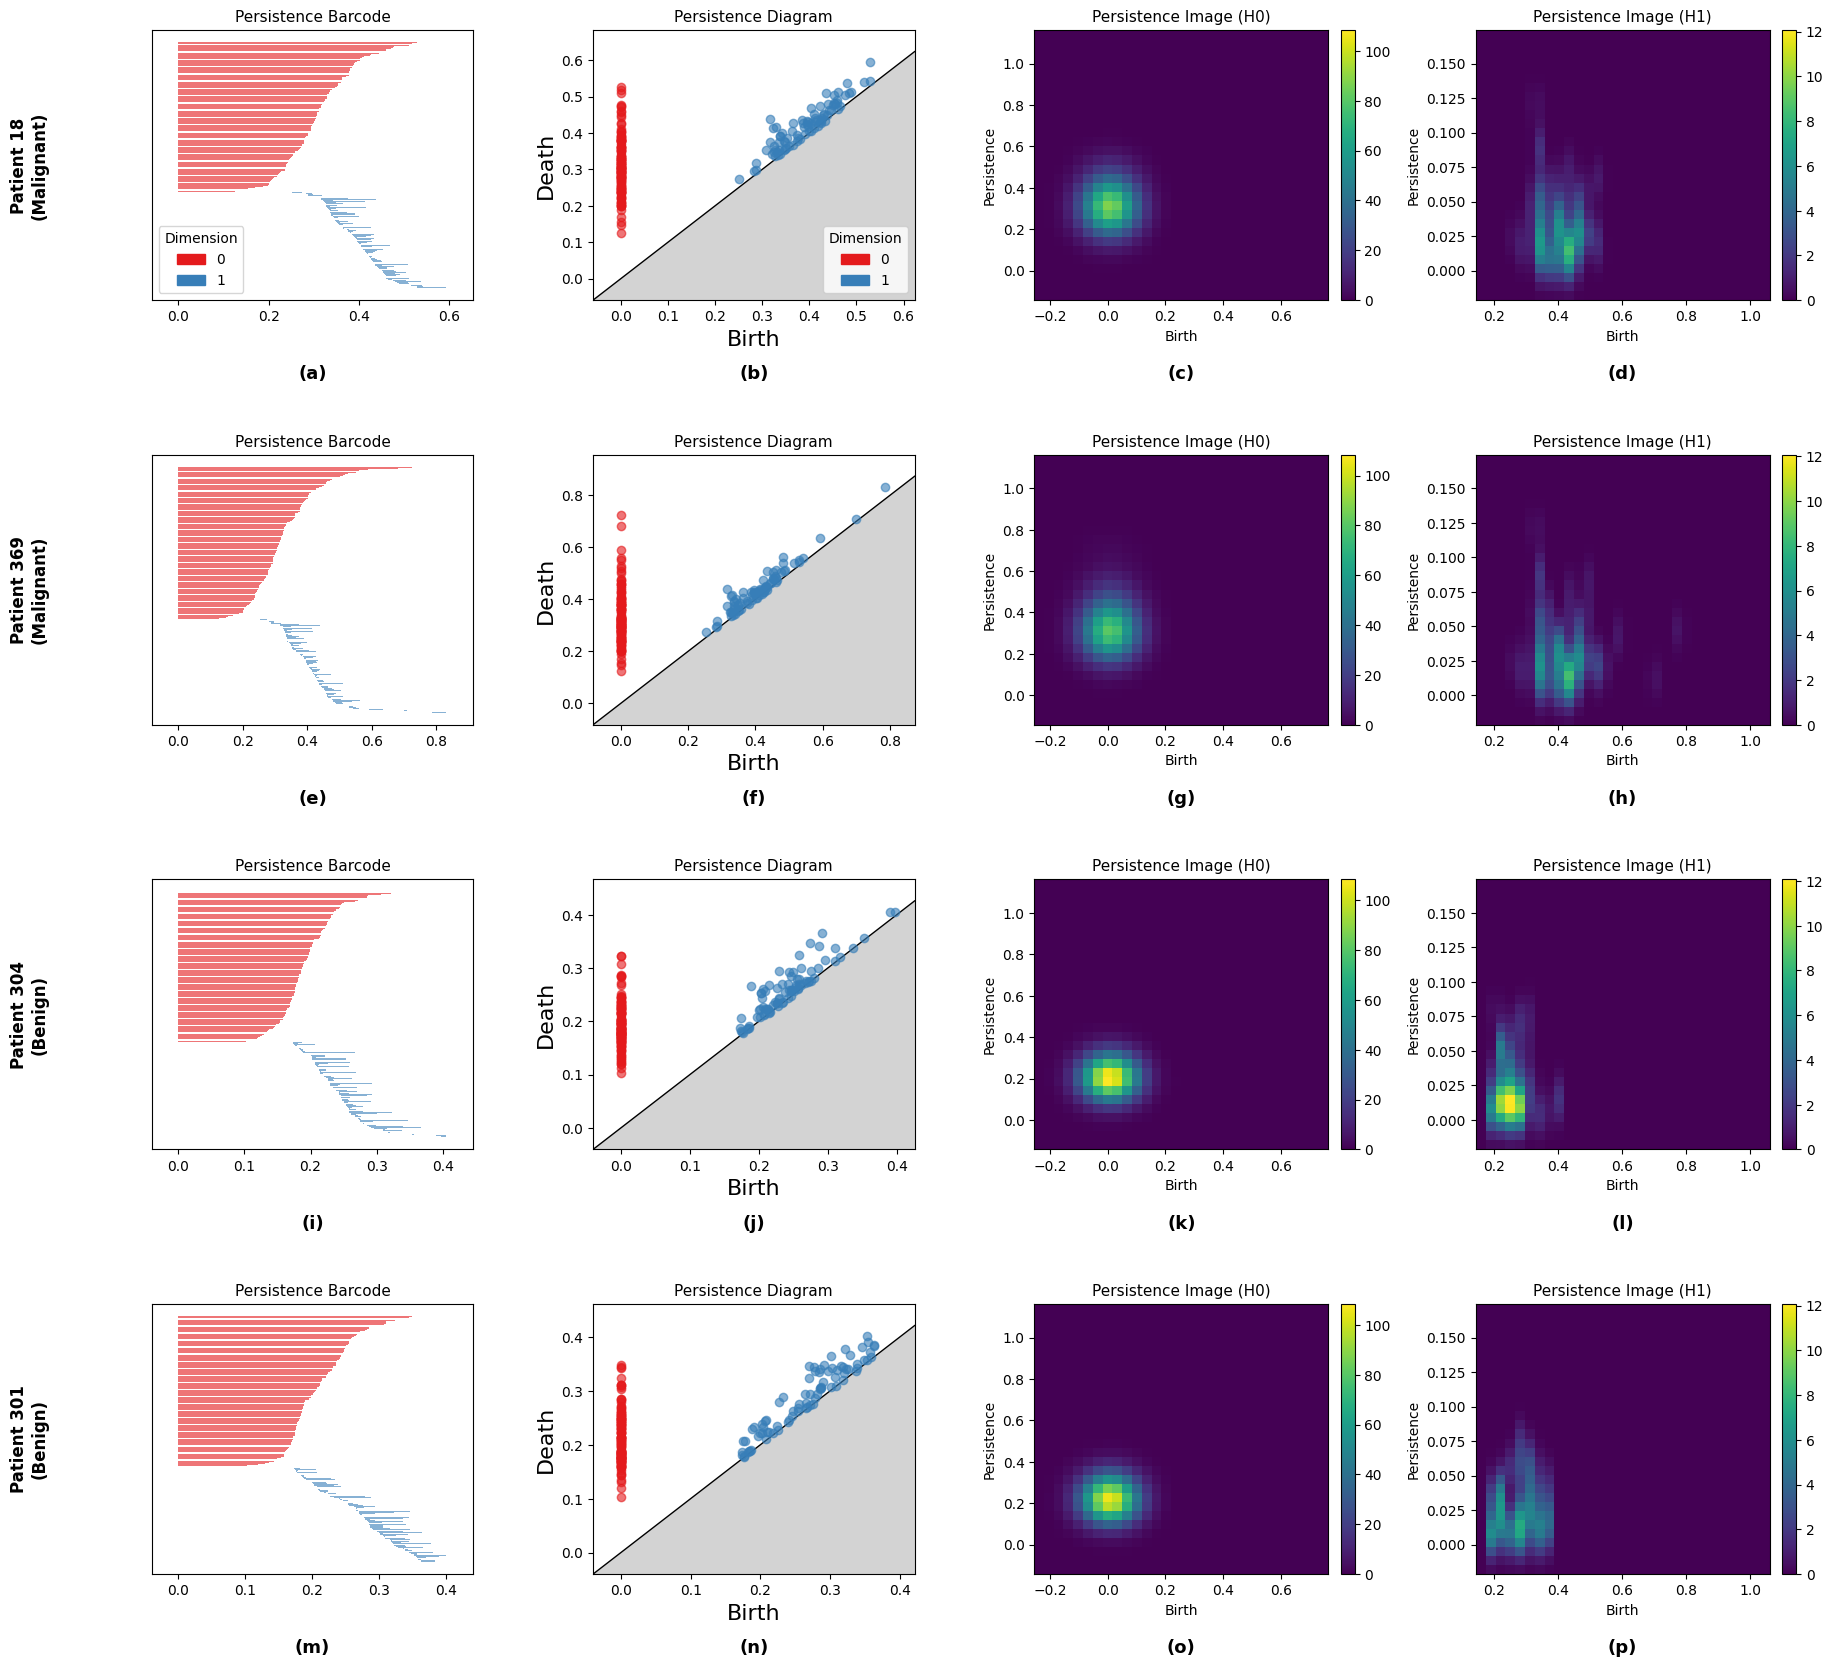

In [8]:
import string
import matplotlib.pyplot as plt
import gudhi

n_rows, n_cols = len(sample_idx), 4
fig, axs = plt.subplots(n_rows, n_cols, figsize=(4.6 * n_cols, 4.2 * n_rows))

letters = list(string.ascii_lowercase)   # (a) ... (p) for 16 panels
k = 0

for r, (i, label) in enumerate(zip(sample_idx, sample_labels)):
    diag_i = [(0, tuple(b)) for b in h0_all[i]] + [(1, tuple(b)) for b in h1_all[i]]

    # (1) Barcode
    ax = axs[r, 0]
    gudhi.plot_persistence_barcode(diag_i, axes=ax, legend=(r == 0))
    ax.set_title('Persistence Barcode', fontsize=11)

    # (2) Diagram
    ax = axs[r, 1]
    gudhi.plot_persistence_diagram(diag_i, axes=ax, legend=(r == 0))
    ax.set_title('Persistence Diagram', fontsize=11)

    # (3) PI H0, (4) PI H1
    for c, (name, img, vmax, rg) in enumerate(
            [('H0', imgs0[i], vmax0, rng0), ('H1', imgs1[i], vmax1, rng1)], start=2):
        ax = axs[r, c]
        im = ax.imshow(img, cmap='viridis', origin='lower', vmin=0, vmax=vmax,
                       extent=[rg[0], rg[1], rg[2], rg[3]], aspect='auto',
                       interpolation='nearest')
        ax.set_title(f'Persistence Image ({name})', fontsize=11)
        ax.set_xlabel('Birth'); ax.set_ylabel('Persistence')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Panel letters under each plot, patient label at the left of each row
    for c in range(n_cols):
        axs[r, c].text(0.5, -0.24, f'({letters[k]})', transform=axs[r, c].transAxes,
                       ha='center', va='top', fontsize=13, fontweight='bold')
        k += 1
    axs[r, 0].annotate(f'Patient {i}\n({label})', xy=(-0.38, 0.5),
                       xycoords='axes fraction', rotation=90,
                       ha='center', va='center', fontsize=12, fontweight='bold')

plt.tight_layout(h_pad=3.5)
plt.savefig('persistence_summary_all_patients.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
# ── 5-fold stratified cross-validation ───────────────────────
#
# Split ratio: 80 % train / 20 % test per fold, rotating across 5 folds.
# PCA, kNN index, and PI transformers are ALL fitted on the training
# partition only and applied to the test partition — no leakage.

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

classifiers = [
    ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=42)),
    ('SVM (RBF)',           SVC(kernel='rbf', probability=True, random_state=42)),
    ('Random Forest',       RandomForestClassifier(n_estimators=100, random_state=42)),
]

feature_labels = ['Original (30 feat)', 'PH features only', 'Original + PH']
all_results    = []

for clf_name, clf in classifiers:
    fold_scores = {label: {'auc': [], 'f1': []} for label in feature_labels}

    for fold, (train_idx, test_idx) in enumerate(cv.split(X_orig, y), 1):
        print(f'[{clf_name}] Fold {fold}/5 — PCA → PH → PI...')

        X_tr_orig, X_te_orig = X_orig[train_idx], X_orig[test_idx]
        y_tr, y_te           = y[train_idx], y[test_idx]

        # ── Step 1: PCA fitted on training data only ──────────
        pca      = PCA(n_components=N_PCA, random_state=42)
        X_tr_pca = pca.fit_transform(X_tr_orig)   # (n_train, d_pca)
        X_te_pca = pca.transform(X_te_orig)        # (n_test,  d_pca)
        print(f'  PCA dim: {X_tr_pca.shape[1]} components')

        # ── Step 2: Persistent homology on PCA-reduced clouds ─
        # Training diagrams: query = train (both reference the training kNN graph)
        tr_h0, tr_h1 = compute_diagrams(X_tr_pca, X_tr_pca)
        # Test diagrams: kNN graph still built from training points only
        te_h0, te_h1 = compute_diagrams(X_tr_pca, X_te_pca)

        # ── Step 3: Fit PI on training diagrams, apply to both ─
        pi_h0, pi_h1 = fit_pi_transformers(tr_h0, tr_h1)
        X_tr_ph      = transform_to_pi(pi_h0, pi_h1, tr_h0, tr_h1)   # (n_train, 50)
        X_te_ph      = transform_to_pi(pi_h0, pi_h1, te_h0, te_h1)   # (n_test,  50)

        # ── Step 4: Evaluate three feature configurations ──────
        feature_sets = {
            'Original (30 feat)': (X_tr_orig,                      X_te_orig),
            'PH features only'  : (X_tr_ph,                        X_te_ph),
            'Original + PH'     : (np.hstack([X_tr_orig, X_tr_ph]),
                                   np.hstack([X_te_orig, X_te_ph])),
        }

        for label, (X_tr, X_te) in feature_sets.items():
            pipe  = Pipeline([('scaler', StandardScaler()), ('clf', clone(clf))])
            pipe.fit(X_tr, y_tr)
            proba = pipe.predict_proba(X_te)[:, 1]
            pred  = pipe.predict(X_te)
            fold_scores[label]['auc'].append(roc_auc_score(y_te, proba))
            fold_scores[label]['f1'].append(f1_score(y_te, pred))

    for label in feature_labels:
        aucs = fold_scores[label]['auc']
        f1s  = fold_scores[label]['f1']
        all_results.append({
            'classifier' : clf_name,
            'features'   : label,
            'AUC_mean'   : np.mean(aucs),
            'AUC_std'    : np.std(aucs),
            'F1_mean'    : np.mean(f1s),
            'F1_std'     : np.std(f1s),
        })

results_df = pd.DataFrame(all_results)
print('\n── Results (sorted by AUC) ────────────────────────────────')
print(results_df.sort_values('AUC_mean', ascending=False).to_string(index=False))

In [ ]:
# ── Summary table: mean ± std per feature set × classifier ───

results_df['AUC'] = results_df.apply(
    lambda r: f"{r['AUC_mean']:.4f} ± {r['AUC_std']:.4f}", axis=1
)
results_df['F1'] = results_df.apply(
    lambda r: f"{r['F1_mean']:.4f} ± {r['F1_std']:.4f}", axis=1
)

summary = results_df[['classifier', 'features', 'AUC', 'F1']]
print(summary.to_string(index=False))

## Comparing the three feature representations: Classical vs Topological vs Combined

The grouped bar chart below summarises the mean cross-validated **AUC** and **F1-score**
(± 1 SD across the 5 folds) achieved by each of the three classifiers under the three feature
representations evaluated above — the classical 30-feature set, the topological (PH) feature
set alone, and the two combined.

In [ ]:
# ── AUC and F1 comparison: two separate figures ──────────────

display_names = {
    'Original (30 feat)': 'Classical',
    'PH features only'  : 'Topological',
    'Original + PH'      : 'Combined',
}

clf_order = [name for name, _ in classifiers]
x         = np.arange(len(clf_order))
width     = 0.25
colors    = ['#4C72B0', '#DD8452', '#55A868']

# --- AUC bar chart: its own figure ---
plt.figure(figsize=(8, 5))
for i, label in enumerate(feature_labels):
    sub = (results_df[results_df['features'] == label]
           .set_index('classifier').loc[clf_order])
    plt.bar(x + (i - 1) * width, sub['AUC_mean'], width,
            yerr=sub['AUC_std'], capsize=4,
            label=display_names[label], color=colors[i])
plt.xticks(x, clf_order, rotation=10)
plt.ylabel('Mean cross-validated AUC')
plt.ylim(0.5, 1.05)
plt.title('Mean CV AUC: Classical vs Topological vs Combined features')
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig('auc_comparison_bar_chart.png', dpi=150, bbox_inches='tight')
plt.show()

# --- F1 bar chart: its own figure ---
plt.figure(figsize=(8, 5))
for i, label in enumerate(feature_labels):
    sub = (results_df[results_df['features'] == label]
           .set_index('classifier').loc[clf_order])
    plt.bar(x + (i - 1) * width, sub['F1_mean'], width,
            yerr=sub['F1_std'], capsize=4,
            label=display_names[label], color=colors[i])
plt.xticks(x, clf_order, rotation=10)
plt.ylabel('Mean cross-validated F1-score')
plt.ylim(0.5, 1.05)
plt.title('Mean CV F1-score: Classical vs Topological vs Combined features')
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig('f1_comparison_bar_chart.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ── Step 6: Save ──────────────────────────────────────────────
results_df.to_csv('/kaggle/working/ph_features.csv', index=False)
print("Saved: final results.csv")